In [1]:
import numpy as np
import os
import tensorflow as tf

SEED = 31415

def set_seed(seed=SEED):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    #os.environ['TF_DETERMINISTIC_OPS'] = '1'

set_seed()

2025-02-04 15:06:32.645513: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1738681592.673326    6690 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1738681592.682121    6690 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-04 15:06:32.726079: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import matplotlib.pyplot as plt
import warnings
from matplotlib import gridspec

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')

warnings.filterwarnings("ignore")

In [3]:
from tensorflow.keras.preprocessing import image_dataset_from_directory

BATCH_SIZE = 64
IMAGE_SIZE = (128, 128)

ds_train_ = image_dataset_from_directory(
    '../datasets/car-or-truck/train',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=True,
)

ds_valid_ = image_dataset_from_directory(
    '../datasets/car-or-truck/valid',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=False,
)


def convert_to_float(image, label):
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)
    return image, label

AUTOTUNE = tf.data.experimental.AUTOTUNE

ds_train = (
    ds_train_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

ds_valid = (
    ds_valid_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

Found 5117 files belonging to 2 classes.


2025-02-04 15:06:37.286757: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 5051 files belonging to 2 classes.


2025-02-04 15:06:38.801532: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


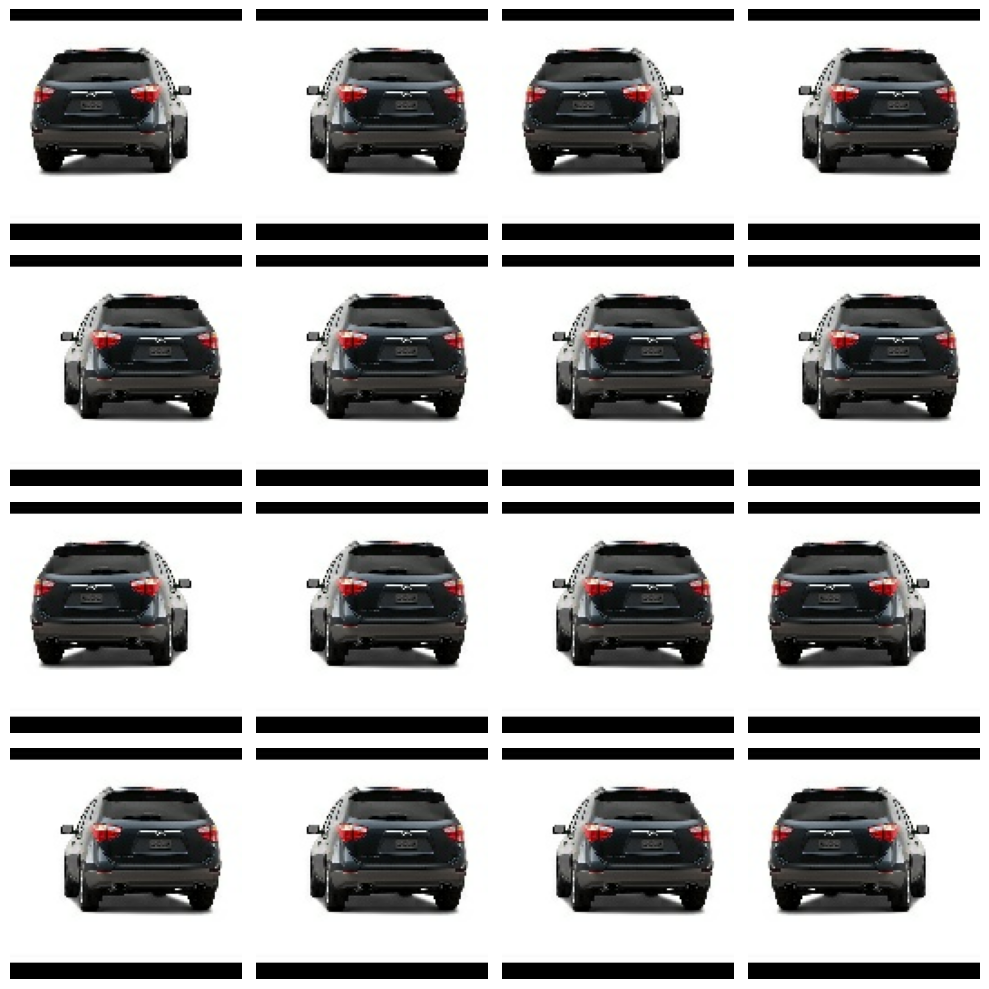

In [4]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    # layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    # layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    # layers.RandomWidth(factor=0.15), # horizontal stretch
    # layers.RandomRotation(factor=0.20),
    # layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

2025-02-04 15:06:39.705860: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1939439].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3322413].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0728623].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.2349428].
Clipping input data to t

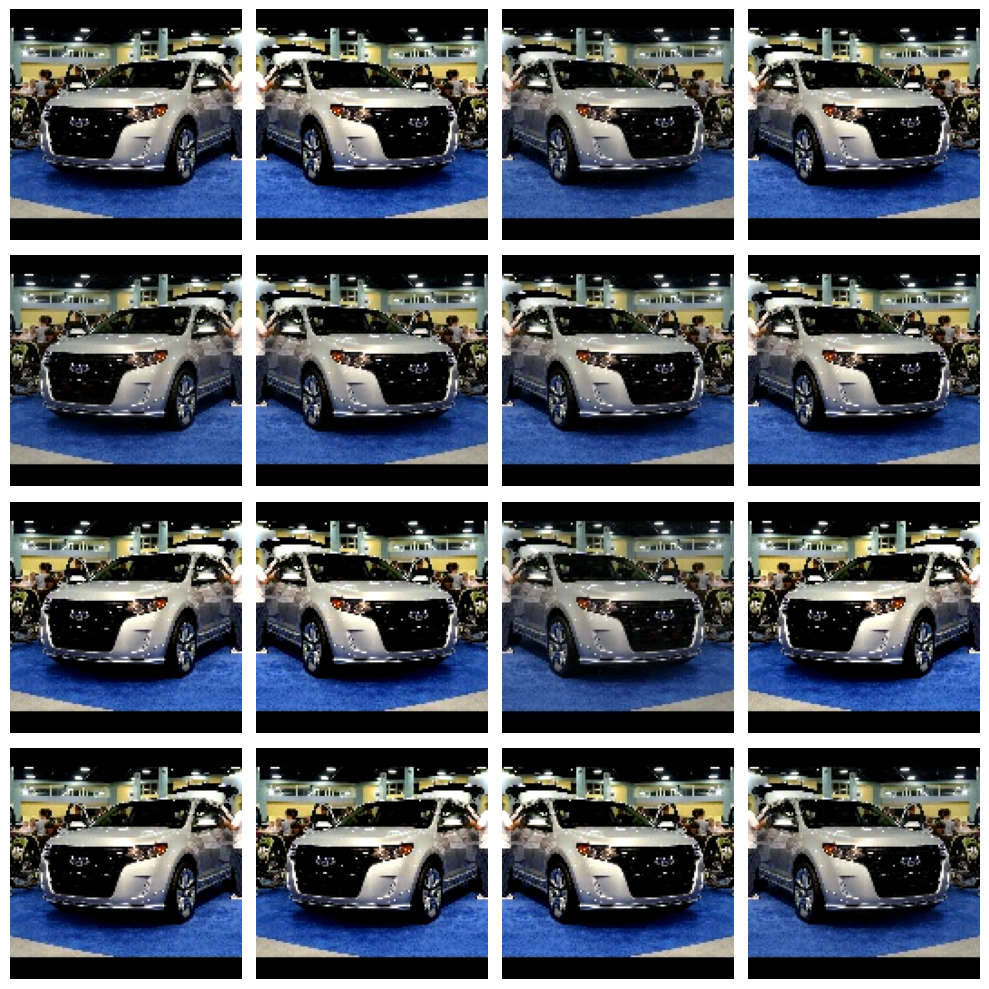

In [5]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    # layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    # layers.RandomWidth(factor=0.15), # horizontal stretch
    # layers.RandomRotation(factor=0.20),
    # layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

2025-02-04 15:06:41.405402: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


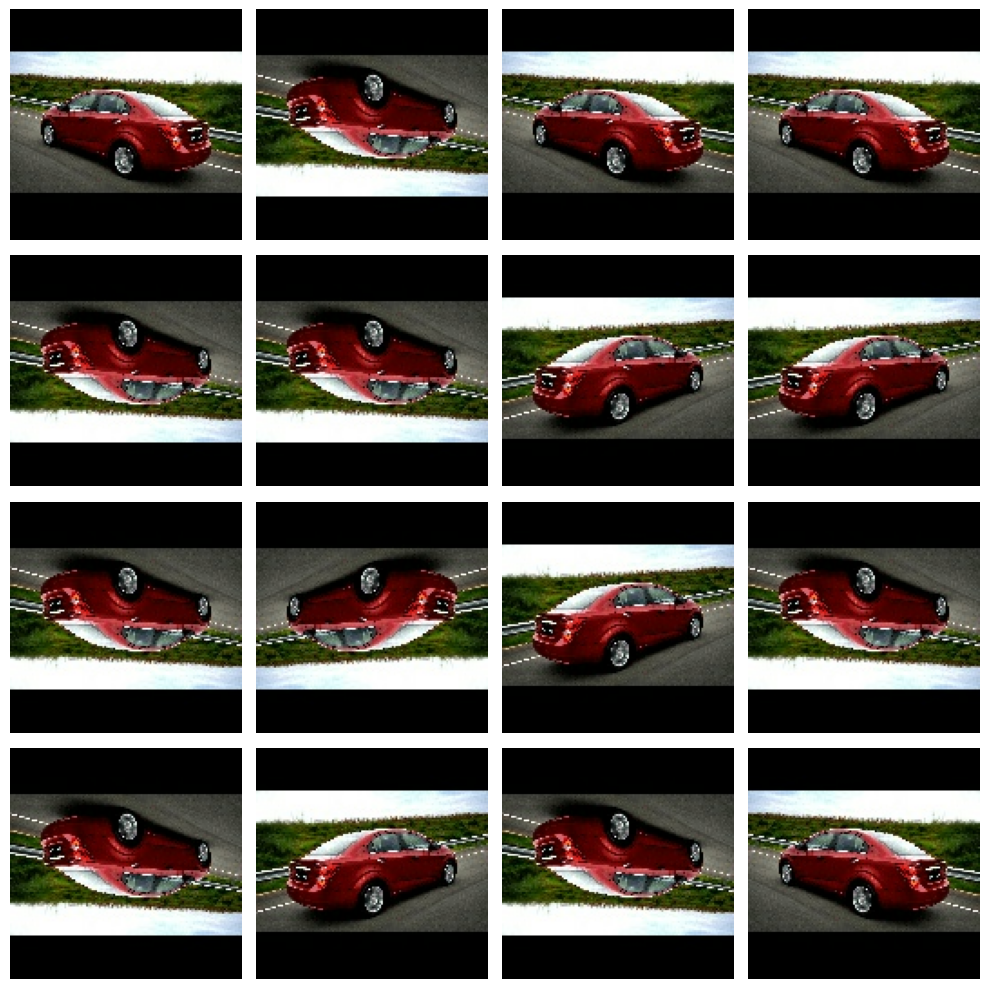

In [6]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    # layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    # layers.RandomWidth(factor=0.15), # horizontal stretch
    # layers.RandomRotation(factor=0.20),
    # layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

2025-02-04 15:06:42.542604: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


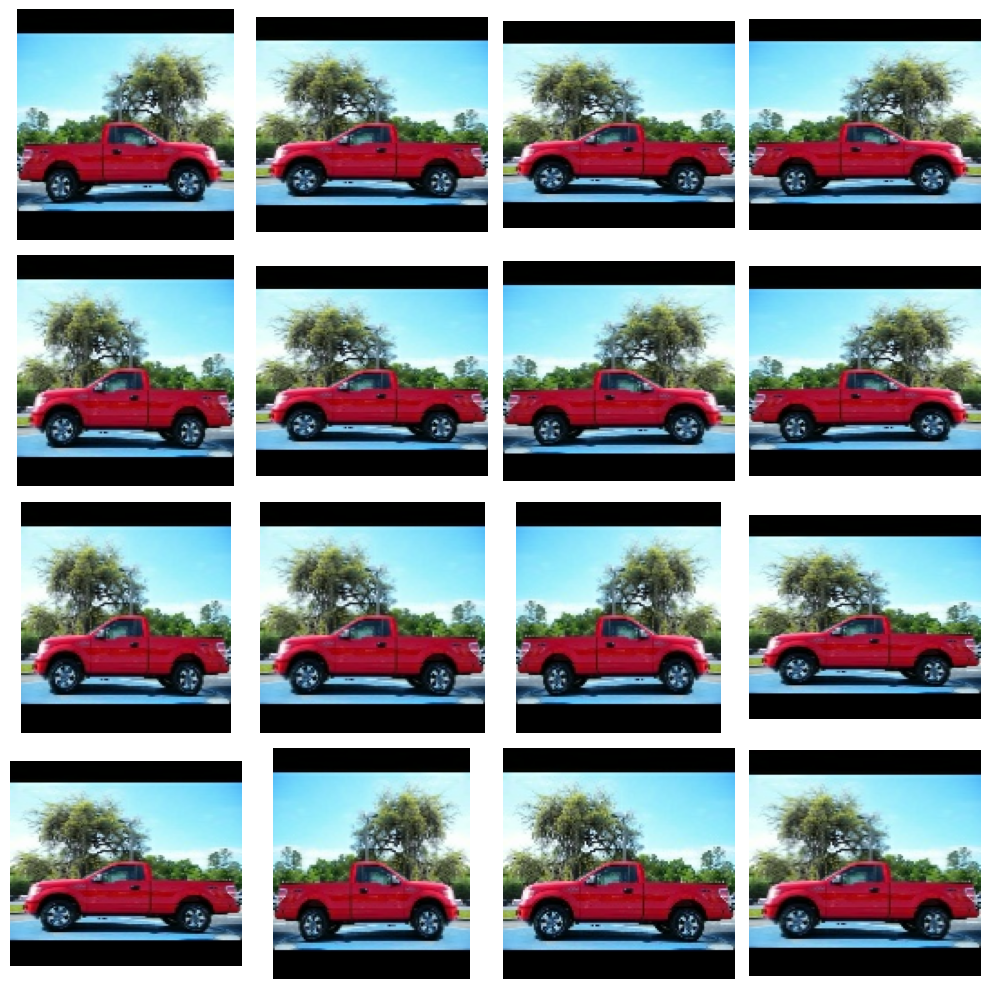

In [7]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    #layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    # layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    layers.RandomWidth(factor=0.15), # horizontal stretch
    # layers.RandomRotation(factor=0.20),
    # layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

2025-02-04 15:06:43.875907: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


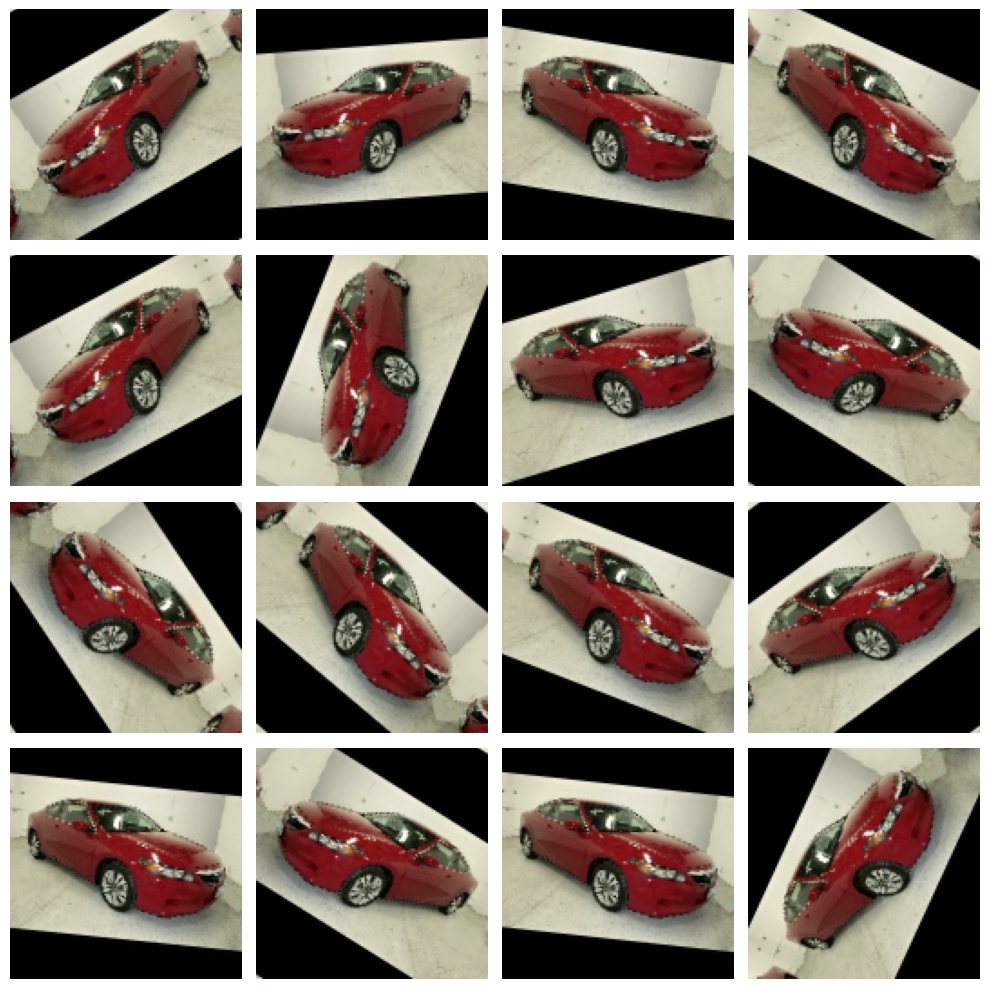

In [8]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    # layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    # layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    # layers.RandomWidth(factor=0.15), # horizontal stretch
    layers.RandomRotation(factor=0.20),
    # layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

2025-02-04 15:06:45.189711: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


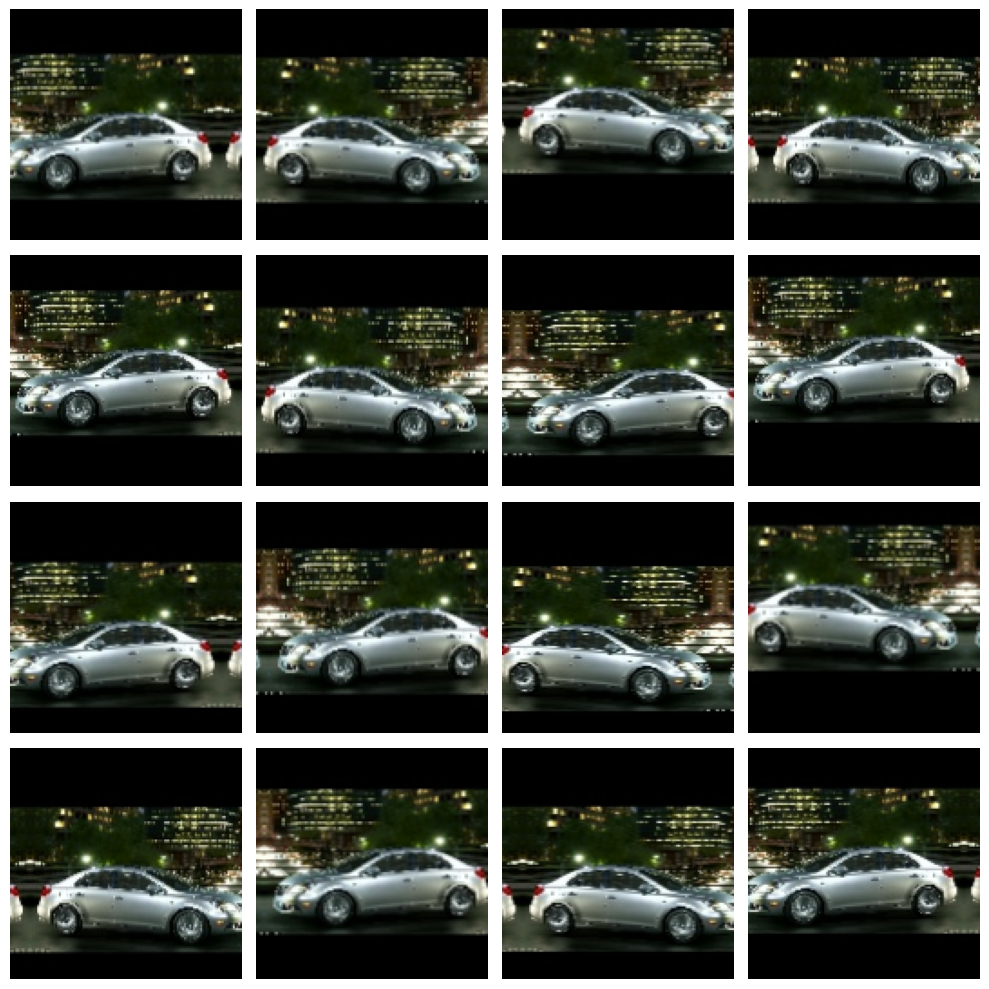

In [9]:
from tensorflow.keras import Sequential, layers

# all of the "factor" parameters indicate a percent-change
augment = Sequential([
    # layers.RandomContrast(factor=0.5),
    layers.RandomFlip(mode='horizontal'), # meaning, left-to-right
    # layers.RandomFlip(mode='vertical'), # meaning, top-to-bottom
    # layers.RandomWidth(factor=0.15), # horizontal stretch
    # layers.RandomRotation(factor=0.20),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
])

ex = next(iter(ds_train.unbatch().map(lambda x, y: x).batch(1)))

plt.figure(figsize=(10,10))
for i in range(16):
    image = augment(ex, training=True)
    plt.subplot(4, 4, i+1)
    plt.imshow(tf.squeeze(image))
    plt.axis('off')
plt.show()

In [10]:
from tensorflow.keras import Sequential, layers

FILTERS = 64
KERNEL_SIZE = 3
PADDING = 'same'
ReLU, SIGMOID = 'relu', 'sigmoid'

model = Sequential([
    layers.InputLayer(input_shape=[*IMAGE_SIZE, 3]),
    
    # Data Augmentation
    layers.RandomContrast(factor=0.10),
    layers.RandomFlip(mode='horizontal'),
    layers.RandomRotation(factor=0.10),

    # Block One
    layers.BatchNormalization(),
    layers.Conv2D(filters=FILTERS, kernel_size=KERNEL_SIZE, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Block Two
    layers.BatchNormalization(),
    layers.Conv2D(filters=2*FILTERS, kernel_size=KERNEL_SIZE, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Block Three
    layers.BatchNormalization(),
    layers.Conv2D(filters=4*FILTERS, kernel_size=KERNEL_SIZE, activation=ReLU, padding=PADDING),
    layers.Conv2D(filters=4*FILTERS, kernel_size=KERNEL_SIZE, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Head
    layers.BatchNormalization(),
    layers.Flatten(),
    layers.Dense(8, activation=ReLU),
    layers.Dense(1, activation=SIGMOID),
])

In [ ]:
import pandas as pd

EPOCHS = 50

optimizer = tf.keras.optimizers.Adam(epsilon=0.01)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

history = model.fit(
    ds_train,
    validation_data=ds_valid,
    epochs=EPOCHS,
)

history_frame = pd.DataFrame(history.history)
history_frame.loc[:, ['loss', 'val_loss']].plot()
history_frame.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot()

Epoch 1/50


2025-02-04 15:06:51.964906: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.
2025-02-04 15:06:52.232510: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.
2025-02-04 15:06:56.656012: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.
2025-02-04 15:06:57.416750: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 134217728 exceeds 10% of free system memory.
2025-02-04 15:06:57.417181: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 268435456 exceeds 10% of free system memory.


 1/80 ━━━━━━━━━━━━━━━━━━━━ 14:43 11s/step - binary_accuracy: 0.4688 - loss: 0.7874

In [ ]:
from IPython.display import display, Markdown

content = f"""
**Q**: **Examine the training curves. What there any sign of overfitting? How does the performance 
of this model compare to other trained models?**<br>
**A**: The learning curves in this model stayed close together for much longer than in previous models. 
This suggests that the augmentation helped prevent overfitting, allowing the model to continue improving.

This model achieved the highest accuracy of all the trained models! This won't always be the case, but it 
shows that a well-designed custom convnet can sometimes perform as well or better than a much larger 
pretrained model. Depending on your application, having a smaller model (which requires fewer resources) 
could be a big advantage.
"""

display(Markdown(content))